### <font color = "gold" > Importer les librairies requises

In [1]:
# Importer les packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

### <font color = "gold" > Importer les données

In [2]:
# Import les données
df = pd.read_excel('Raisin_Dataset.xlsx')
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


Ces données sont issues d'images de variétés de raisins secs Kecimen et Besni. Au total, 900 raisins secs ont été utilisés, dont 450 provenant des deux variétés, et 7 variables morphologiques ont été extraites. Pour plus de détails vous pouvez consulter le site https://archive.ics.uci.edu/dataset/850/raisin.
\
L'objectif de ce projet est de réduire la dimension des données afin de pouvoir mieux voir les deux catégories de raisins à travers un scatter plot.

**Source :** UCI Machine Learning Repository, dataset « Raisin »
- Page du dataset : https://archive.ics.uci.edu/dataset/850/raisin
- Téléchargement direct : https://archive.ics.uci.edu/static/public/850/raisin.zip
- Fichier utilisé : Raisin_Dataset.xlsx

####  <font color = "gold" > Explorer les données

In [3]:
# Dimension des données
df.shape

(900, 8)

In [4]:
#infos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             900 non-null    int64  
 1   MajorAxisLength  900 non-null    float64
 2   MinorAxisLength  900 non-null    float64
 3   Eccentricity     900 non-null    float64
 4   ConvexArea       900 non-null    int64  
 5   Extent           900 non-null    float64
 6   Perimeter        900 non-null    float64
 7   Class            900 non-null    object 
dtypes: float64(5), int64(2), object(1)
memory usage: 56.4+ KB


In [5]:
# Décrire les données
df.describe()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
count,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,87804.127778,430.929950,254.488133,0.781542,91186.090000,0.699508,1165.906636
std,39002.111390,116.035121,49.988902,0.090318,40769.290132,0.053468,273.764315
min,25387.000000,225.629541,143.710872,0.348730,26139.000000,0.379856,619.074000
25%,59348.000000,345.442898,219.111126,0.741766,61513.250000,0.670869,966.410750
50%,78902.000000,407.803951,247.848409,0.798846,81651.000000,0.707367,1119.509000
75%,105028.250000,494.187014,279.888575,0.842571,108375.750000,0.734991,1308.389750
max,235047.000000,997.291941,492.275279,0.962124,278217.000000,0.835455,2697.753000


In [6]:
# Visualiser les classes suivant les deux premières variables
fig = px.scatter(data_frame=df, x = 'Area', y = 'MajorAxisLength', color = df.Class.values)
fig.show()

In [7]:
# Visualiser les classes suivant les trois premières variables
fig = px.scatter_3d(data_frame=df, x = 'Area', y = 'MajorAxisLength', z = 'MinorAxisLength', color = df.Class.values)
fig.show()

#### <font color = "gold" > Matrice des données

In [8]:
# Les variables utilisées pour le PCA
x = df.iloc[:, :-1].values
x[:5]

array([[8.75240000e+04, 4.42246011e+02, 2.53291155e+02, 8.19738392e-01,
        9.05460000e+04, 7.58650579e-01, 1.18404000e+03],
       [7.51660000e+04, 4.06690687e+02, 2.43032436e+02, 8.01805234e-01,
        7.87890000e+04, 6.84129570e-01, 1.12178600e+03],
       [9.08560000e+04, 4.42267048e+02, 2.66328318e+02, 7.98353619e-01,
        9.37170000e+04, 6.37612812e-01, 1.20857500e+03],
       [4.59280000e+04, 2.86540559e+02, 2.08760042e+02, 6.84989217e-01,
        4.73360000e+04, 6.99599385e-01, 8.44162000e+02],
       [7.94080000e+04, 3.52190770e+02, 2.90827533e+02, 5.64011330e-01,
        8.14630000e+04, 7.92771926e-01, 1.07325100e+03]])

###<font color = "gold" > PCA from scrath

##### <font color = "wheat" >Standardiser les données

In [9]:
# Standardiser chaque variable : z = (x - moyenne) / écart-type
# (normalize() ramenait chaque LIGNE à une norme 1 : les variables de grande échelle
#  comme Area et ConvexArea dominaient alors toute la variance)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x = scaler.fit_transform(x)
x[:5]

array([[-7.18636823e-03,  9.75769473e-02, -2.39581868e-02,
         4.23141637e-01, -1.57090276e-02,  1.10674264e+00,
         6.62739660e-02],
       [-3.24217186e-01, -2.09012072e-01, -2.29292219e-01,
         2.24476390e-01, -3.04248197e-01, -2.87776790e-01,
        -1.61252453e-01],
       [ 7.82924055e-02,  9.77583458e-02,  2.36987967e-01,
         1.86239068e-01,  6.21133511e-02, -1.15824974e+00,
         1.55944681e-01],
       [-1.07428573e+00, -1.24505128e+00, -9.15273485e-01,
        -1.06962266e+00, -1.07616471e+00,  1.71147419e-03,
        -1.17591488e+00],
       [-2.15393369e-01, -6.78957894e-01,  7.27353556e-01,
        -2.40982731e+00, -2.38623145e-01,  1.74525897e+00,
        -3.38638561e-01]])

In [10]:
# Transformer x standardisé en dataframe
x_df = pd.DataFrame(x, columns=df.columns[:-1])

##### <font color = "wheat" > Matrice de covariance


In [11]:
# Matrice de covariance covmat
cov_mat = x_df.cov()
cov_mat

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
Area,1.001112,0.933812,0.907658,0.336480,0.997027,-0.013514,0.962421
MajorAxisLength,0.933812,1.001112,0.728840,0.584258,0.946082,-0.204092,0.979066
MinorAxisLength,0.907658,0.728840,1.001112,-0.027714,0.896648,0.145483,0.828337
Eccentricity,0.336480,0.584258,-0.027714,1.001112,0.348598,-0.361463,0.448343
ConvexArea,0.997027,0.946082,0.896648,0.348598,1.001112,-0.054863,0.977699
Extent,-0.013514,-0.204092,0.145483,-0.361463,-0.054863,1.001112,-0.173642
Perimeter,0.962421,0.979066,0.828337,0.448343,0.977699,-0.173642,1.001112


##### <font color = "wheat" >Vecteurs propres et valeurs propres

In [12]:
from numpy import linalg as LA
# Vecteurs propres et valeurs propres
# eigh : pour une matrice symétrique (comme la covariance) -> valeurs réelles (pas de nombres complexes)
val_propres, vecteurs_propres = LA.eigh(cov_mat)

# eigh renvoie les valeurs propres en ordre croissant -> trier en ordre décroissant
idx = np.argsort(val_propres)[::-1]
val_propres = val_propres[idx]
vecteurs_propres = vecteurs_propres[:, idx]

for i in range(len(val_propres)):
    print(f'Vecteur propre {i + 1}: \n {vecteurs_propres[:, i]}')
    print(f'Valeur propre {i + 1}: \n {val_propres[i]}')
    print('------------------------------')


Vecteur propre 1: 
 [-0.44828422 -0.4432398  -0.38938118 -0.20297098 -0.45093833  0.05636836
 -0.45082374]
Valeur propre 1: 
 4.837663792829394
------------------------------
Vecteur propre 2: 
 [-0.11609991  0.13658724 -0.37492246  0.61082321 -0.08761633 -0.66734439
  0.03417227]
Valeur propre 2: 
 1.4548048893462138
------------------------------
Vecteur propre 3: 
 [ 0.00548378 -0.10054797  0.23604354 -0.62852206  0.0366724  -0.73198093
  0.04430077]
Valeur propre 3: 
 0.629148521834685
------------------------------
Vecteur propre 4: 
 [ 0.11113906 -0.49520464  0.6558767   0.42629865 -0.0558117  -0.10905256
 -0.3398651 ]
Valeur propre 4: 
 0.05688772093928008
------------------------------
Vecteur propre 5: 
 [ 0.61104765 -0.08757032 -0.38457775 -0.07510412  0.39241075 -0.05685884
 -0.5551508 ]
Valeur propre 5: 
 0.021832526925834914
------------------------------
Vecteur propre 6: 
 [-0.09983439 -0.68557712 -0.2390332   0.05356014  0.47120104  0.02345199
  0.48726906]
Valeur propr

##### <font color = "wheat" >Composantes principales

In [13]:
# matrice des composantes principales
comp_prin_matrix = np.dot(x, vecteurs_propres)

In [14]:
# Créer une liste des noms des différentes composantes
df_pca = pd.DataFrame(comp_prin_matrix, columns = ['PC' + str(i + 1) for i in range(7)])
df_pca.head()


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
0,-0.076994,-0.453328,-1.089214,-0.026789,-0.141386,0.013058,-0.003708
1,0.475376,0.445368,0.016372,0.115945,-0.121995,0.013809,-0.005672
2,-0.372109,0.802008,0.786487,0.264963,-0.062190,-0.043419,-0.007209
3,2.622445,-0.302564,0.482721,-0.099597,0.115331,0.042284,-0.013387
4,0.962054,-2.967763,0.452154,-0.299883,-0.175771,-0.052468,-0.006949


##### <font color = "wheat" >Calcul des parts de variance (pdv)

In [15]:
# Dictionnaire des proportion de variance
dic = {
       'val_propres' : val_propres,
       'proportion' : (val_propres/val_propres.sum())*100
        }
pdv = pd.DataFrame(dic)
pdv['pct_cumule'] = pdv['proportion'].cumsum()
pdv.index = ['PC' + str(i + 1) for i in range(7)]
pdv

,val_propres,proportion,pct_cumule
PC1,4.837664,69.032694,69.032694
PC2,1.454805,20.759835,89.792529
PC3,0.629149,8.977850,98.770379
PC4,0.056888,0.811779,99.582158
PC5,0.021833,0.311547,99.893704
PC6,0.006437,0.091860,99.985564
PC7,0.001012,0.014436,100.000000


##### <font color = "wheat" >Visualiser la proportion variance

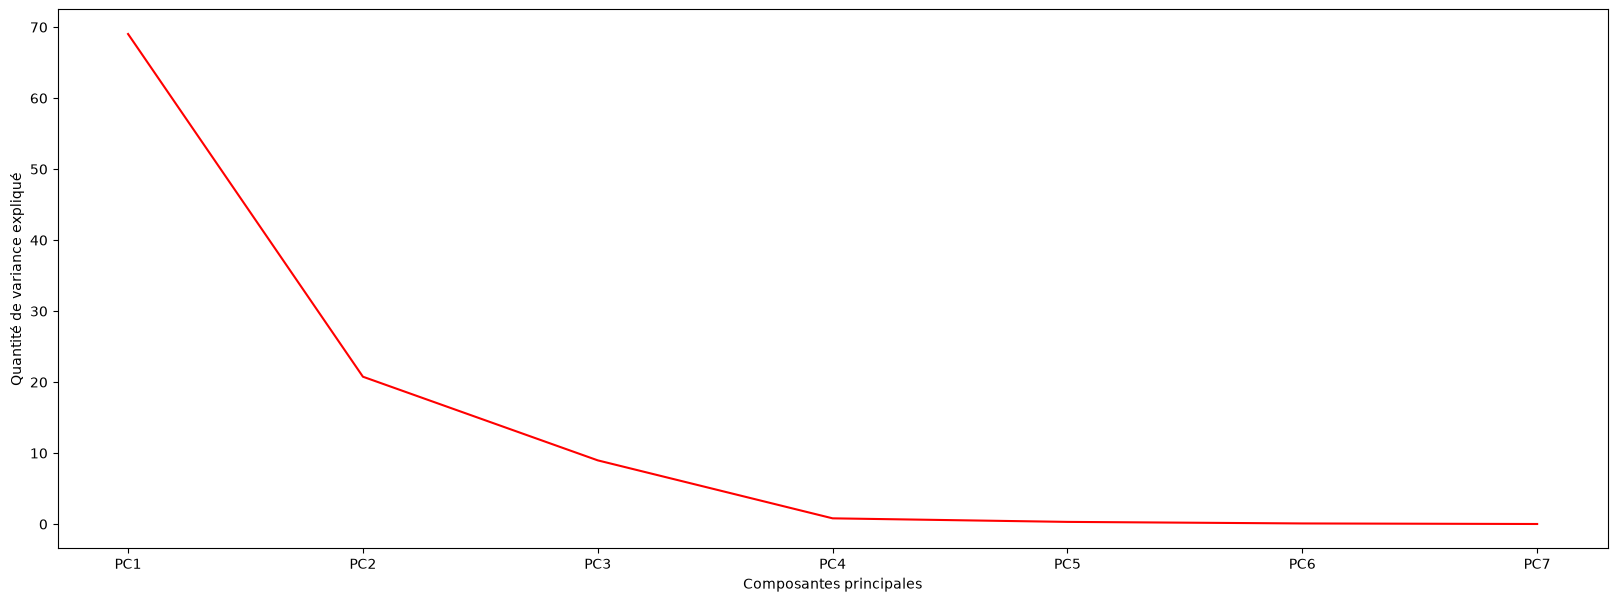

In [16]:
# Plot des parts de variance de chaque composantes
plt.figure(figsize=(20, 7))
plt.plot(df_pca.columns, pdv['proportion'], c='r')
plt.ylabel('Quantité de variance expliqué')
plt.xlabel('Composantes principales')
plt.show()

In [17]:
# Part de variance des deux composantes
print(f'Part de variance des deux composantes : {pdv.iloc[1, 2]}')

Part de variance des deux composantes : 89.79252929009324


##### <font color = "wheat" > Nouveau jeu de données réduit

In [18]:
# Selectionner les composantes qui maximisent la part de variance

New_df = df_pca.iloc[:, :2]
New_df.head()

,PC1,PC2
0,-0.076994,-0.453328
1,0.475376,0.445368
2,-0.372109,0.802008
3,2.622445,-0.302564
4,0.962054,-2.967763


##### <font color = "wheat" >Visualiser les donneées suivant les deux premiers composantes

In [19]:
# Visualiser les classes suivant les deux composantes
fig = px.scatter(New_df.apply(np.real), x = 'PC1', y = 'PC2', color = df.Class.values)
fig.show()


### <font color = "gold" > PCA from sklearn

In [20]:
# Importer PCA model
from sklearn.decomposition import PCA

In [21]:
# Initier l'instance PCA avec 2 composantes
pca = PCA(n_components=2)
# Matrice des composantes avec fonction fit_transform
feature_pca = pca.fit_transform(x)

In [22]:
# Nouveau dataframe des deux composantes
New_def_1 = pd.DataFrame(feature_pca, columns = ['PC1', 'PC2'])
New_def_1.head()

,PC1,PC2
0,0.076994,0.453328
1,-0.475376,-0.445368
2,0.372109,-0.802008
3,-2.622445,0.302564
4,-0.962054,2.967763


In [23]:
# Part de variance des 2 composantes
round(sum(pca.explained_variance_ratio_*100), 2)

np.float64(89.79)

In [24]:
# Visualiser les classes suivant les deux composantes
# Visualiser les classes suivant les deux composantes
fig = px.scatter(data_frame=New_def_1, x = 'PC1', y = 'PC2', color = df.Class.values)
fig.show()

### <font color = "gold" > Interprétation du PCA

In [25]:
# install mlxtend
!pip install mlxtend


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


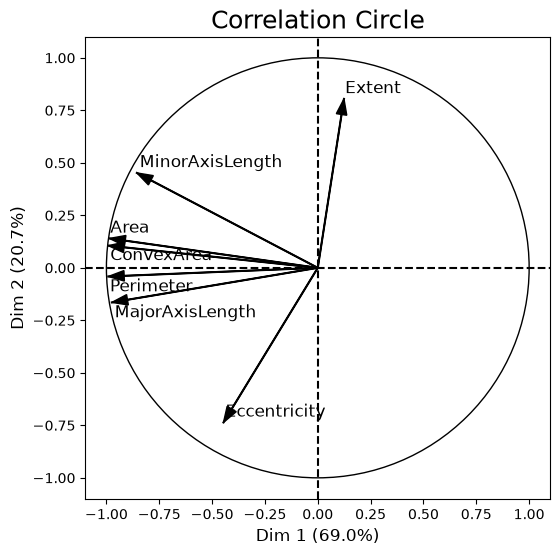

In [26]:
# import plot_pca_correlation_graph
from mlxtend.plotting import plot_pca_correlation_graph
figure, correlation_matrix = plot_pca_correlation_graph(x,
                                                        df.columns[:-1],
                                                       dimensions= (1,2))

In [27]:
# Affichar la matrice de corrélation
correlation_matrix 

,Dim 1,Dim 2
Area,-0.985439,0.139956
MajorAxisLength,-0.974350,-0.164654
MinorAxisLength,-0.855956,0.451963
Eccentricity,-0.446180,-0.736337
ConvexArea,-0.991274,0.105620
Extent,0.123912,0.804472
Perimeter,-0.991022,-0.041194


In [28]:
# matrice de correlation entre les variables
df[df.columns[:-1]].corr()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
Area,1.000000,0.932774,0.906650,0.336107,0.995920,-0.013499,0.961352
MajorAxisLength,0.932774,1.000000,0.728030,0.583608,0.945031,-0.203866,0.977978
MinorAxisLength,0.906650,0.728030,1.000000,-0.027683,0.895651,0.145322,0.827417
Eccentricity,0.336107,0.583608,-0.027683,1.000000,0.348210,-0.361061,0.447845
ConvexArea,0.995920,0.945031,0.895651,0.348210,1.000000,-0.054802,0.976612
Extent,-0.013499,-0.203866,0.145322,-0.361061,-0.054802,1.000000,-0.173449
Perimeter,0.961352,0.977978,0.827417,0.447845,0.976612,-0.173449,1.000000


##### <font color = "wheat" > Interprétation

- **PC1 (69 % de la variance) : la taille du raisin.** Elle est très fortement corrélée à Area, ConvexArea, Perimeter et MajorAxisLength (|r| > 0,97), ainsi qu'à MinorAxisLength (|r| ≈ 0,86). Ces variables de taille sont aussi très corrélées entre elles (cf. matrice de corrélation) : elles portent pratiquement la même information, que la PCA résume en un seul axe. Le signe de l'axe est arbitraire (il diffère entre la PCA « from scratch » et celle de sklearn), seule la direction compte.
- **PC2 (21 % de la variance) : la forme du raisin.** Elle oppose Extent (r ≈ +0,80, raisin compact qui remplit sa boîte englobante) à Eccentricity (r ≈ −0,74, raisin allongé).

### <font color = "gold" > Conclusion

Après standardisation, les deux premières composantes conservent **89,8 %** de l'information des 7 variables. Sur le scatter plot (PC1, PC2), les deux variétés se séparent essentiellement le long de PC1 : **Besni** regroupe en moyenne les gros raisins (Area moyenne ≈ 112 000 contre ≈ 63 000 pour **Kecimen**), Kecimen est un peu plus compact et moins allongé. Les deux nuages se chevauchent néanmoins dans la zone centrale.

Une régression logistique entraînée sur ces deux composantes seulement atteint environ **88 % d'accuracy** sur un jeu de test (cellule suivante). La réduction 7 → 2 dimensions garde donc l'essentiel de l'information utile pour distinguer les variétés.

## <font color='gold'> Clustering : K-Means et CAH

On cherche maintenant à regrouper les raisins **sans utiliser la variable Class** (apprentissage non supervisé), en suivant les étapes du notebook Customer_Segmentation. On comparera ensuite les classes trouvées avec les vraies catégories.

### <font color='gold'> Preparation des données

In [29]:
# renommer les index
df.index = ['Raisin' + str(i+1) for i in range(len(df))]
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
Raisin1,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
Raisin2,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
Raisin3,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
Raisin4,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
Raisin5,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [30]:
# Données en format matriciel (sans la variable Class : le clustering est non supervisé)
x = df.iloc[:, :-1].values
x[:5]

array([[8.75240000e+04, 4.42246011e+02, 2.53291155e+02, 8.19738392e-01,
        9.05460000e+04, 7.58650579e-01, 1.18404000e+03],
       [7.51660000e+04, 4.06690687e+02, 2.43032436e+02, 8.01805234e-01,
        7.87890000e+04, 6.84129570e-01, 1.12178600e+03],
       [9.08560000e+04, 4.42267048e+02, 2.66328318e+02, 7.98353619e-01,
        9.37170000e+04, 6.37612812e-01, 1.20857500e+03],
       [4.59280000e+04, 2.86540559e+02, 2.08760042e+02, 6.84989217e-01,
        4.73360000e+04, 6.99599385e-01, 8.44162000e+02],
       [7.94080000e+04, 3.52190770e+02, 2.90827533e+02, 5.64011330e-01,
        8.14630000e+04, 7.92771926e-01, 1.07325100e+03]])

In [31]:
# Importer normalize
from sklearn.preprocessing import normalize
# Normaliser x
x = normalize(x)
x[:5]

array([[6.94970090e-01, 3.51158254e-03, 2.01121723e-03, 6.50899941e-06,
        7.18965789e-01, 6.02394156e-06, 9.40167708e-03],
       [6.90232276e-01, 3.73454805e-03, 2.23171157e-03, 7.36279504e-06,
        7.23501461e-01, 6.28220619e-06, 1.03011056e-02],
       [6.96027277e-01, 3.38810788e-03, 2.04028104e-03, 6.11600660e-06,
        7.17944751e-01, 4.88460761e-06, 9.25861986e-03],
       [6.96285203e-01, 4.34405920e-03, 3.16487825e-03, 1.03846859e-05,
        7.17630995e-01, 1.06061814e-05, 1.27978033e-02],
       [6.97980415e-01, 3.09568633e-03, 2.55631576e-03, 4.95754662e-06,
        7.16043454e-01, 6.96830645e-06, 9.43366133e-03]])

In [32]:
# Importer PCA
from sklearn.decomposition import PCA
#Instantier le modèle PCA avec n_components = 2
pca_model= PCA(n_components = 2)
# Matrice des 2 composantes
feature_pca = pca_model.fit_transform(x)
# Convertir la matrice features_pca en dataframe
New_df = pd.DataFrame(feature_pca, columns = ['PC1', 'PC2'])

In [33]:
# Part de variance des 2 composantes
np.round(sum(pca_model.explained_variance_ratio_)*100, 2)

np.float64(99.88)

In [34]:
# Function de visualisation du diagramme en barre des nombres d'observations.
def bar_plot(val):
  fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
  fig.show()

In [35]:
# Function de visualisuation des classes
def scatter_plot(New_df,Pred):
  fig = px.scatter(New_df, x='PC1', y='PC2', color=Pred.astype(str))
  fig.show()

### <font color='gold'> Kmeans

In [36]:
# Importer KMeans
from sklearn.cluster import KMeans

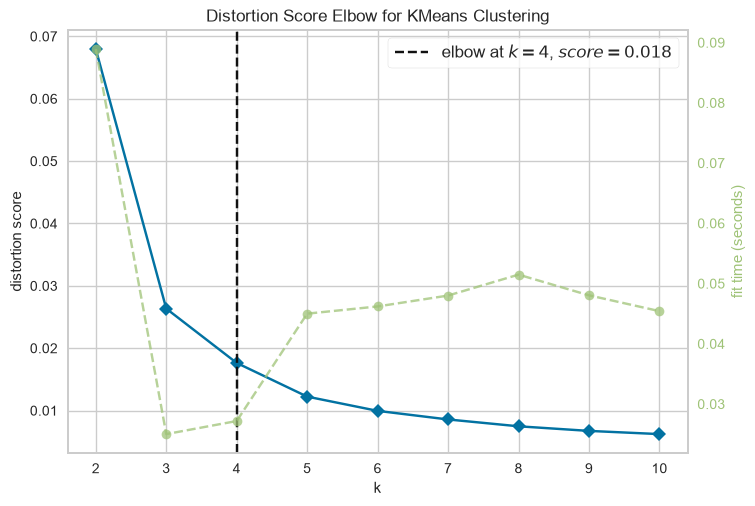

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [37]:
# importer KELbowVisualizer
import setuptools  # charge le module distutils de remplacement pour yellowbrick
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init='random', max_iter=500)
kmeans_model._estimator_type = "clusterer"  # contournement : yellowbrick 1.5 + scikit-learn ≥ 1.6
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

**Choix de k = 2.** La courbe du coude ne présente pas de cassure nette (le point proposé par KElbowVisualizer varie entre 3 et 5 d'une exécution à l'autre). On retient k = 2 : c'est le nombre de variétés de raisins du jeu de données, ce qui permet de comparer les classes trouvées avec les vraies catégories.

In [38]:
# instantier le modèle
kmeans_model = KMeans(n_clusters = 2, init = 'random', max_iter=500, random_state=42)
# Entrainer le modèle
kmeans_model.fit(x)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",500
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",42
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


#### <font color='teal'> Prédiction

In [39]:
# Prediction de la partition des données
kmeans_partition = kmeans_model.predict(x)
# Afficher la partition
kmeans_partition[: 100]

array([0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0], dtype=int32)

In [40]:
# Nombre d'observations dans chaque classe
val = pd.Series(kmeans_partition).value_counts()
val

0    780
1    120
Name: count, dtype: int64

In [41]:
# Diagramme en barre des nombres d'observations
bar_plot(val)

In [42]:
# Visualiser les classes
scatter_plot(New_df, kmeans_partition)

##### <font color='teal'> Indice de silhouette de la partition du Kmeans

In [43]:
# Silhouette score
from sklearn.metrics import silhouette_score
siil_kmeans = silhouette_score(x, kmeans_partition)
print("Silhouette score for KMeans clustering: ", siil_kmeans)

Silhouette score for KMeans clustering:  0.6312801766532526


### <font color='gold'> CAH

In [44]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import  linkage, dendrogram

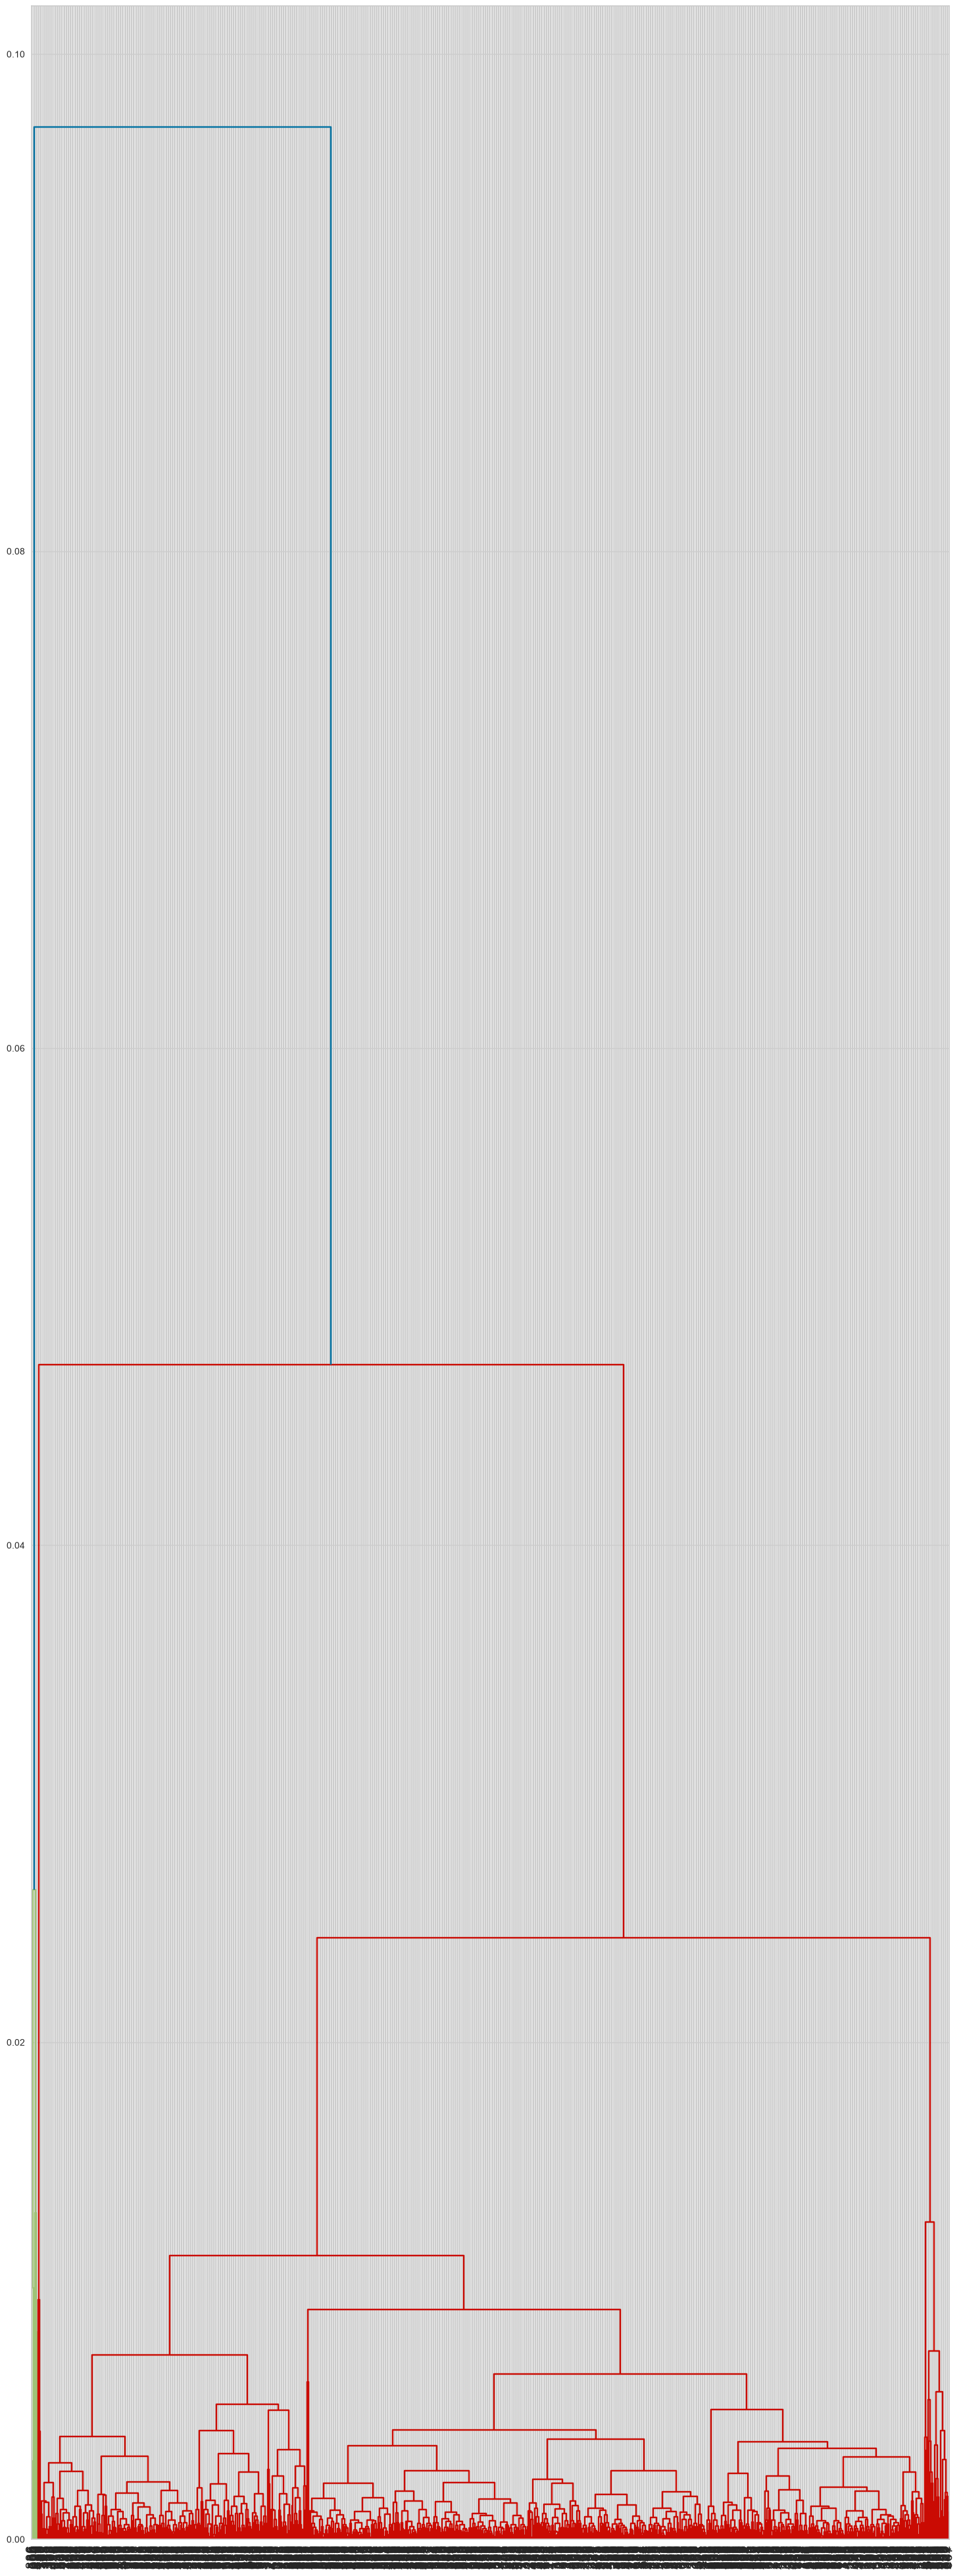

In [45]:
# Visualiser le dendrograme
import matplotlib.pyplot as plt
Z = linkage(x, 'average')# matrice des liaisons
plt.figure(figsize=(18, 50))
dendro = dendrogram(Z, leaf_font_size=15, orientation = 'top')

In [46]:
from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters = 2, linkage = 'average')
# Entrainer le modèle
cah_model.fit(x)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",2
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" is accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and affinity is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'average'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",None
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False


In [47]:
# Prédire la partition des données
cah_partition = cah_model.fit_predict(x)
# Afficher la partition
cah_partition[: 100]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [48]:
# Nombre d'observations dans chaque classe
val1  = pd.Series(cah_partition).value_counts()
val1

0    894
1      6
Name: count, dtype: int64

In [49]:
# Diagramme en barre des nombres d'observations
bar_plot(val1)

In [50]:
# Visualiser les classes
scatter_plot(New_df, cah_partition)

In [51]:
# Silhouette score
sil_cah = silhouette_score(x, cah_partition)
print("Silhouette score for Agglomerative clustering: ", sil_cah)

Silhouette score for Agglomerative clustering:  0.9038563893771413


In [52]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [siil_kmeans, sil_cah]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [53]:
# les indidivus
cluster_name = []
for i in range(2):
    cluster_name.append(list(df.index[kmeans_partition == i]))

In [54]:
# Les individus de la classe 0
print("Individus de la classe 0 :")
print(cluster_name[0])

Individus de la classe 0 :
['Raisin1', 'Raisin2', 'Raisin3', 'Raisin4', 'Raisin5', 'Raisin6', 'Raisin7', 'Raisin8', 'Raisin10', 'Raisin11', 'Raisin12', 'Raisin13', 'Raisin14', 'Raisin15', 'Raisin17', 'Raisin18', 'Raisin19', 'Raisin20', 'Raisin21', 'Raisin22', 'Raisin23', 'Raisin25', 'Raisin26', 'Raisin27', 'Raisin28', 'Raisin29', 'Raisin31', 'Raisin32', 'Raisin33', 'Raisin34', 'Raisin35', 'Raisin37', 'Raisin38', 'Raisin39', 'Raisin40', 'Raisin41', 'Raisin42', 'Raisin43', 'Raisin44', 'Raisin45', 'Raisin46', 'Raisin47', 'Raisin48', 'Raisin49', 'Raisin50', 'Raisin51', 'Raisin52', 'Raisin53', 'Raisin55', 'Raisin56', 'Raisin57', 'Raisin58', 'Raisin59', 'Raisin60', 'Raisin61', 'Raisin62', 'Raisin63', 'Raisin64', 'Raisin65', 'Raisin66', 'Raisin67', 'Raisin68', 'Raisin69', 'Raisin70', 'Raisin71', 'Raisin74', 'Raisin75', 'Raisin76', 'Raisin77', 'Raisin78', 'Raisin79', 'Raisin80', 'Raisin81', 'Raisin84', 'Raisin85', 'Raisin87', 'Raisin88', 'Raisin90', 'Raisin91', 'Raisin92', 'Raisin93', 'Raisin9

#### <font color='teal'> Comparer les classes trouvées avec les vraies catégories

In [55]:
# Classes K-Means / vraies catégories
pd.crosstab(df.Class, kmeans_partition, rownames=['Vraie catégorie'], colnames=['Classe K-Means'])

Classe K-Means,0,1
Vraie catégorie,,
Besni,379,71
Kecimen,401,49


In [56]:
# Classes CAH / vraies catégories
pd.crosstab(df.Class, cah_partition, rownames=['Vraie catégorie'], colnames=['Classe CAH'])

Classe CAH,0,1
Vraie catégorie,,
Besni,446,4
Kecimen,448,2


##### <font color='teal'> Interprétation du clustering

- **Silhouette** : la CAH obtient le meilleur score (≈ 0,90 contre ≈ 0,63 pour K-Means), mais sa partition est déséquilibrée : 894 raisins d'un côté et **6 raisins atypiques** de l'autre. La liaison `average` isole quelques points extrêmes, ce qui gonfle la silhouette sans produire de groupes utiles. On retient donc **K-Means** (780 / 120 raisins) comme meilleur modèle.
- **Comparaison avec les variétés** : aucune des deux méthodes ne retrouve Kecimen et Besni. Les deux classes K-Means contiennent chacune un mélange des deux variétés (379 Besni / 401 Kecimen et 71 / 49).
- **Pourquoi ?** `normalize` ramène chaque raisin à une norme 1. Comme Area et ConvexArea sont bien plus grandes que les autres variables, elles occupent presque toute la norme et l'information de taille disparaît : il ne reste que le rapport ConvexArea / Area (la régularité du contour). C'est ce qui sépare les deux classes K-Means : ConvexArea / Area ≈ 1,03 pour la classe 0 (forme régulière) contre ≈ 1,09 pour la classe 1 (forme irrégulière, moins compacte : Extent 0,66 contre 0,71). Pour la même raison, la PCA sur les données normalisées affiche 99,9 % de variance sur 2 composantes (contre 89,8 % après standardisation dans la première partie).

### <font color='gold'> Meilleur modèle (K-Means) pour le déploiement

In [57]:
from scipy.spatial.distance import cdist

# Partition du meilleur modèle
best_partition = kmeans_partition
# Calculer les centroïdes
classes = np.unique(best_partition)
centroides = np.array([x[best_partition == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
def predire_classe(nouvelle_obs):
    obs = normalize(np.array(nouvelle_obs, dtype=float).reshape(1, -1))
    distances = cdist(obs, centroides)
    return classes[distances.argmin()]

In [58]:
# Test rapide
print("Classe prédite  :", predire_classe(df.iloc[0, :-1].values))
print("Classe réelle du K-Means:", best_partition[0])

Classe prédite  : 0
Classe réelle du K-Means: 0


#### <font color='teal'> Interpréter les classes

Avant de livrer l'application, il faut savoir **ce que représente chaque classe**, pour afficher un
message compréhensible par l'utilisateur final. On regarde le profil moyen de chaque classe.

In [59]:
# Profil moyen de chaque classe
profil = df.iloc[:, :-1].groupby(best_partition).mean().round(2)
profil

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
0,89513.35,431.65,257.87,0.78,92333.57,0.71,1165.96
1,76694.18,426.24,232.54,0.81,83727.49,0.66,1165.59


In [60]:
# Noms des classes
noms_classes = {
    0: "raisin à forme régulière",
    1: "raisin à forme irrégulière",
}

In [61]:
# Sauvegarder le modèle de clustering pour l'application Streamlit
import joblib
joblib.dump({'modele': 'K-Means', 'variables': list(df.columns[:-1]), 'classes': classes,
             'centroides': centroides, 'noms_classes': noms_classes}, 'raisin_clustering.joblib')

['raisin_clustering.joblib']

### <font color = "gold" > Sauvegarde du modèle pour le déploiement

In [62]:
# Pipeline : standardisation + PCA, puis une régression logistique sur (PC1, PC2)
# pour prédire la variété d'un nouveau raisin dans l'application Streamlit
import joblib
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X = df.iloc[:, :-1]
y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2)),
    ('clf', LogisticRegression()),
])
model.fit(X_train, y_train)
print(f'Accuracy sur le jeu de test : {model.score(X_test, y_test):.3f}')

# Réentraîner sur toutes les données et sauvegarder
model.fit(X, y)
joblib.dump(model, 'raisin_pca_model.joblib')

Accuracy sur le jeu de test : 0.878


['raisin_pca_model.joblib']